# Mejora acotada de un prompt YAML

[English](prompt-search.ipynb) | Español | [Caso y modelamiento](README.es.md) | [PDF de lectura](prompt-search.es.pdf)

Un asistente de deudas sintéticas busca la mayor deuda viable entre 200, 300 y 600, en uno o dos pagos y con consentimiento explícito. Cada ejemplo contiene un historial fijo; el asistente genera la siguiente respuesta.

Solo cambia el prompt de política. Modelo, runtime, optimizador y evaluador permanecen fijos. Es búsqueda de prompts, no mejora recursiva.

**Resultado registrado:** ningún candidato aceptado. Validación del baseline: 75,0%; mayor puntaje candidato: 83,3%, con un incumplimiento. El límite de tokens detuvo la búsqueda antes de la prueba final.

Ambas notebooks presentan la misma ejecución. Usó el protocolo v2 y el objetivo original en inglés; el objetivo actual en español pertenece a v3 y todavía no tiene resultados medidos.

## 1. Componentes del experimento

El [runtime](prompt_search.py) carga la política, los ejemplos sintéticos y la configuración fija de evaluación. Las secciones siguientes presentan entradas, etapas de búsqueda y resultados registrados.

In [1]:
LANGUAGE = 'es'
from pathlib import Path
import importlib.util
import json
import sys
import yaml
from dotenv import load_dotenv
from IPython.display import Markdown, HTML, display

relative = Path("research/proposals/case-0003-debt-negotiation")
CASE = next((base / relative for base in [Path.cwd(), *Path.cwd().parents]
             if (base / relative / "prompt_search.py").is_file()), None)
if CASE is None:
    raise RuntimeError("Open this notebook inside the thinking-harness checkout")
spec = importlib.util.spec_from_file_location("case3_search", CASE / "prompt_search.py")
search = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = search
spec.loader.exec_module(search)
load_dotenv(CASE / ".env", override=False)  # Never display credentials.

def text(en, es):
    return es if LANGUAGE == "es" else en

view_spec = importlib.util.spec_from_file_location("case3_view", CASE / "notebook_view.py")
view_module = importlib.util.module_from_spec(view_spec)
view_spec.loader.exec_module(view_module)
view = view_module.EvidenceView(LANGUAGE)

cases = search.load_cases()
seed = yaml.safe_load((CASE / "prompt.yaml").read_text())
search.get_prompt(seed)
settings = yaml.safe_load((CASE / "config.yaml").read_text())
config = search.Config(**settings)
config.validate()
print(text("Local inputs loaded. No API calls.", "Entradas locales cargadas. Sin llamadas a la API."))

Entradas locales cargadas. Sin llamadas a la API.


## 2. Política y golden set

[prompt.yaml](prompt.yaml) contiene la política modificable. [golden-set.yaml](golden-set.yaml) contiene 18 ejemplos sintéticos. El [objetivo](README.es.md#objetivo) define las reglas.

Desarrollo informa las propuestas; validación selecciona candidatos; la prueba final queda fuera del bucle. Con capacidad mensual de 170, B es viable en dos pagos de 150, pero C no lo es. La diferencia `cuota - capacidad` es una característica derivada. No se entrenan pesos del modelo.

In [2]:
example = next(c for c in cases if c["id"] == "development-limited")
view.inputs(seed, cases, example, search.visible(example))

Partición,Ejemplos
Desarrollo,6
Validación,6
Prueba final,6


Rol,Mensaje
assistant,Could you pay debt C in one payment of 600?
user,No. My monthly limit is 170.


## 3. Búsqueda y evaluación

Una respuesta es exitosa si su decisión coincide con la referencia, cumple las reglas y aprueba una rúbrica LLM fija de consistencia, pertinencia y claridad. El puntaje es la fracción de respuestas exitosas. Un candidato debe tener cero incumplimientos y mejorar el puntaje al menos `min_gain`.

`p000` es la semilla genérica. `p001` se genera una vez desde el objetivo y los ejemplos de desarrollo y sirve como baseline de comparación. Los candidatos posteriores cambian solo el campo `prompt` del YAML. La selección es discreta; no se calcula un gradiente.

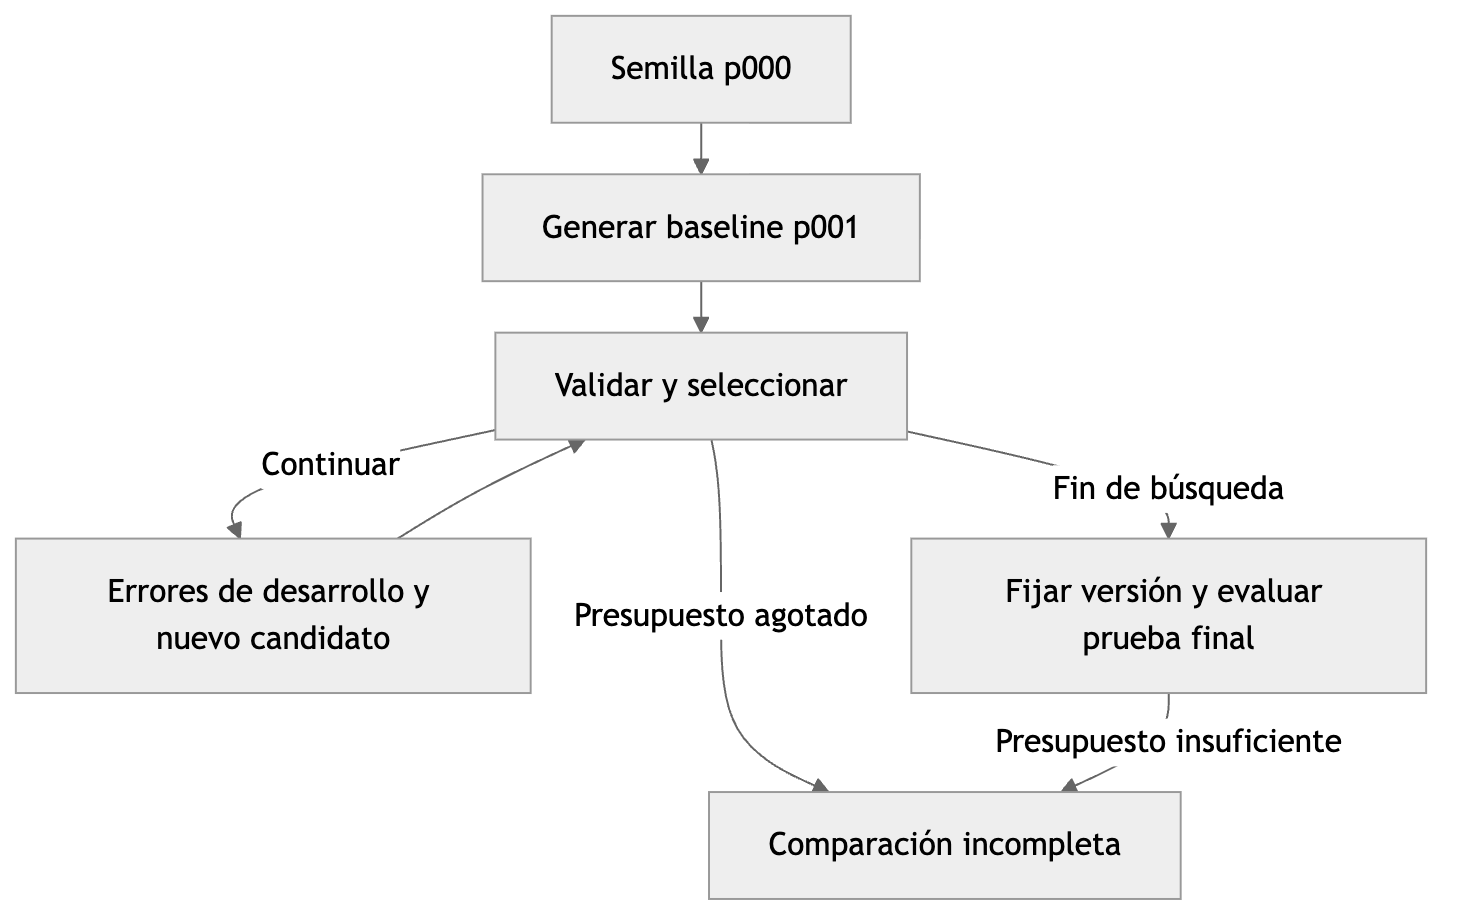

El presupuesto común cubre propuestas, evaluación y prueba final. Un corte por presupuesto puede dejar la comparación incompleta. Los costos se estiman con los precios configurados. El juez todavía no está calibrado.

In [3]:
RUN_LIVE = False
REPLAY_REPORT = "results/20261017T011558Z-f5eca942/report.json"
view.bounds(config)

Parámetro,Valor
Modelo,gpt-5.4-mini-2026-03-17
Rondas / candidatos por ronda,3 / 2
Repeticiones de evaluación,2
Meta / ganancia mínima,1.0 / 0.01
Presupuesto de tokens,"100,000"
Límite de costo estimado,USD 1.00


## 4. Ejecución registrada

El reporte guardado contiene la genealogía de versiones, las decisiones del evaluador y el consumo medido. Ambos idiomas remiten a esta misma evidencia.

In [4]:
report = None
if RUN_LIVE and REPLAY_REPORT:
    raise ValueError("Choose live execution OR replay, not both")
if RUN_LIVE:
    # Fresh charged run each time this cell executes. No automatic retries.
    report = search.run_search(config)
    report_path = Path(report["evidence_dir"]) / "report.json"
    print(text("Replay path:", "Ruta para volver a mostrar el reporte:"), report_path.relative_to(CASE))
elif REPLAY_REPORT:
    report_path = (CASE / REPLAY_REPORT).resolve()
    if not report_path.is_relative_to(CASE.resolve()):
        raise ValueError("Use a report inside the case folder")
    report = json.loads(report_path.read_text())
    if report.get("protocol") not in search.REPLAY_PROTOCOLS or report.get("mode") != "live":
        raise ValueError("Expected a live report from this protocol, not a test double")
    # Replay uses saved evidence, never current settings or a new API call.
    print(text("Replaying saved evidence. No API calls.", "Lectura de evidencia guardada. Sin llamadas a la API."))
else:
    print(text("No execution record selected.", "Sin registro de ejecución seleccionado."))

Lectura de evidencia guardada. Sin llamadas a la API.


## 5. Versiones de la política

Cada versión conserva su texto original y su versión padre. La tabla distingue el puntaje de validación de la admisibilidad. La comparación desplegable muestra los cambios respecto del padre.

In [5]:
if report is not None:
    view.versions(report, report_path)

Versión,Padre,Validación,Incumplimientos,Conservada
p000,-,-,-,-
p001,p000,75.0%,1,Sí
p002,p001,75.0%,2,-
p003,p001,66.7%,2,-
p004,p001,83.3%,1,-


Antes,Después
repayment advisor. Respond clearly,"synthetic debt negotiation assistant. Follow the structured decision rules exactly and keep replies brief. First, determine whether the customer has explicitly declined negotiation. If so, stop politely and state that no agreement has been made. If monthly capacity is unknown, ask one concise question for the amount they can afford each month. Do not assume zero. If capacity is known, offer the largest feasible debt among A (200), B (300), and C (600), without inventing discounts, interest, or extra terms. Negotiate at most one debt. For this pilot, prefer one payment when the full debt fits within capacity; otherwise use two equal monthly payments. If no allowed plan fits the stated capacity, say so and stop. If the customer’s reply is ambiguous, clarify it. Confirm an agreement only after explicit consent"
customer.,"exact debt and payment plan. Never treat a missing or unclear reply as acceptance. If the customer explicitly accepts the exact offered debt and plan, record the agreement in the response. Otherwise, continue only with the appropriate next step."


Antes,Después
replies,the next reply
"First, determine whether","Use at most one debt. Never invent discounts, interest, penalties, execution, or extra terms. Decision order: 1) If"
has,-
"declined negotiation. If so,","refuses to negotiate or asks to stop,"
state that,say
-,2)
the amount they can afford each month.,their monthly amount.
-,3)
offer,choose
"A (200), B (300), and C (600), without inventing discounts, interest, or extra terms. Negotiate at most one debt. For this pilot, prefer","A=200, B=300, C=600. Prefer"


Antes,Después
Follow,Be brief and follow
"exactly and keep replies brief. First, determine whether",exactly. 1) If
has,-
"declined negotiation. If so,","refuses negotiation or asks to stop,"
politely,immediately
-,2)
the amount they can afford each month.,their monthly amount.
-,3)
offer,negotiate at most one debt and choose
"A (200), B (300), and C (600), without inventing","A=200, B=300, C=600. 4) Use only authorized terms: one payment or two equal monthly payments. Do not invent"


Antes,Después
replies,the next message
"First, determine whether",1) If
has,-
"declined negotiation. If so,","refuses to negotiate or asks to stop,"
state that,say
-,2)
-,exactly
-,3)
-,choose at most one debt and
"A (200), B (300), and C (600), without inventing discounts, interest, or extra terms. Negotiate at most one debt. For this pilot,","A=200, B=300, C=600. Use the smallest plan that fits the capacity:"


## 6. Evaluación por etapa

Cada tabla incluye todas las respuestas evaluadas. Las secciones desplegables contienen el historial completo, la respuesta y la justificación del evaluador. Se conserva el idioma original de las respuestas. La redacción de referencia es ilustrativa, no un objetivo de coincidencia literal.

In [6]:
if report is not None:
    view.evaluations(report)

Ejemplo,Repetición,Decisión,Resultado
validation-unknown,1,ask · - · 0 × 0,Cumple
validation-unknown,2,ask · - · 0 × 0,Cumple
validation-largest,1,offer · B · 1 × 300,No cumple
validation-largest,2,offer · B · 1 × 300,No cumple
validation-limited,1,offer · A · 2 × 100,Cumple
validation-limited,2,offer · A · 2 × 100,Cumple
validation-infeasible,1,offer · A · 2 × 100,No cumple
validation-infeasible,2,stop · - · 0 × 0,Cumple
validation-declined,1,stop · - · 0 × 0,Cumple
validation-declined,2,stop · - · 0 × 0,Cumple


Ejemplo,Repetición,Decisión,Resultado
development-unknown,1,ask · - · 0 × 0,Cumple
development-unknown,2,ask · - · 0 × 0,Cumple
development-largest,1,offer · B · 1 × 300,No cumple
development-largest,2,offer · B · 1 × 300,No cumple
development-limited,1,offer · A · 2 × 100,No cumple
development-limited,2,offer · A · 2 × 100,No cumple
development-infeasible,1,stop · - · 0 × 0,Cumple
development-infeasible,2,stop · - · 0 × 0,Cumple
development-declined,1,stop · - · 0 × 0,Cumple
development-declined,2,stop · - · 0 × 0,Cumple


Ejemplo,Repetición,Decisión,Resultado
validation-unknown,1,ask · - · 0 × 0,Cumple
validation-unknown,2,ask · - · 0 × 0,Cumple
validation-largest,1,offer · B · 1 × 300,No cumple
validation-largest,2,offer · B · 1 × 300,No cumple
validation-limited,1,stop · - · 0 × 0,No cumple
validation-limited,2,offer · A · 2 × 100,Cumple
validation-infeasible,1,stop · - · 0 × 0,Cumple
validation-infeasible,2,stop · - · 0 × 0,Cumple
validation-declined,1,stop · - · 0 × 0,Cumple
validation-declined,2,stop · - · 0 × 0,Cumple


Ejemplo,Repetición,Decisión,Resultado
validation-unknown,1,ask · - · 0 × 0,Cumple
validation-unknown,2,ask · - · 0 × 0,Cumple
validation-largest,1,offer · B · 1 × 300,No cumple
validation-largest,2,offer · B · 1 × 300,No cumple
validation-limited,1,offer · A · 2 × 100,Cumple
validation-limited,2,offer · A · 2 × 100,Cumple
validation-infeasible,1,offer · A · 2 × 100,No cumple
validation-infeasible,2,stop · C · 0 × 0,No cumple
validation-declined,1,stop · - · 0 × 0,Cumple
validation-declined,2,stop · - · 0 × 0,Cumple


Ejemplo,Repetición,Decisión,Resultado
development-unknown,1,ask · - · 0 × 0,Cumple
development-unknown,2,ask · - · 0 × 0,Cumple
development-largest,1,offer · B · 1 × 300,No cumple
development-largest,2,offer · A · 1 × 200,No cumple
development-limited,1,offer · A · 2 × 100,No cumple
development-limited,2,offer · B · 2 × 150,Cumple
development-infeasible,1,stop · - · 0 × 0,Cumple
development-infeasible,2,stop · - · 0 × 0,Cumple
development-declined,1,stop · - · 0 × 0,Cumple
development-declined,2,stop · - · 0 × 0,Cumple


Ejemplo,Repetición,Decisión,Resultado
validation-unknown,1,ask · - · 0 × 0,Cumple
validation-unknown,2,ask · - · 0 × 0,Cumple
validation-largest,1,offer · B · 1 × 300,No cumple
validation-largest,2,offer · B · 1 × 300,No cumple
validation-limited,1,offer · A · 2 × 100,Cumple
validation-limited,2,offer · A · 2 × 100,Cumple
validation-infeasible,1,stop · - · 0 × 0,Cumple
validation-infeasible,2,stop · - · 0 × 0,Cumple
validation-declined,1,stop · - · 0 × 0,Cumple
validation-declined,2,stop · - · 0 × 0,Cumple


## 7. Resultado registrado

La comparación final es distinta de la validación. Este piloto sintético pequeño no establece significancia estadística ni efectividad real.

In [7]:
if report is not None:
    view.summary(report)

Medida,Valor registrado
Baseline / versión conservada,p001 / p001
Motivo de parada,Presupuesto
Llamadas a la API,148
Tokens,"83,815"
Costo estimado,USD 0.10261125
Comparación final,Incompleta


## Evidencia

[Reporte](results/20261017T011558Z-f5eca942/report.json) · [Consumo](results/20261017T011558Z-f5eca942/usage.jsonl) · [Procedencia](results/20261017T011558Z-f5eca942/provenance.json)

[Caso y modelamiento](README.es.md) · [English](prompt-search.ipynb)